⚡ XGBoost Avg Single-Transaction Latency: 3.852 ms
⚡ LightGBM Avg Single-Transaction Latency: 2.736 ms

================ XGBoost PaySim Results ================
Precision-Recall AUC (PR-AUC) : 0.9792
ROC-AUC Score                : 0.9931
Fraud Recall (Sensitivity)    : 98.25%
False Positive Rate (FPR)     : 0.1274%
Confusion Matrix:
 [[91734   117]
 [    4   224]]

================ LightGBM PaySim Results ================
Precision-Recall AUC (PR-AUC) : 0.9818
ROC-AUC Score                : 0.9927
Fraud Recall (Sensitivity)    : 98.25%
False Positive Rate (FPR)     : 0.1426%
Confusion Matrix:
 [[91720   131]
 [    4   224]]

PR-AUC Plot saved to 'reports/figures/pr_curve_paysim.png'

--- Generating SHAP Feature Importance ---
SHAP Plot saved to 'reports/figures/shap_summary_paysim.png'


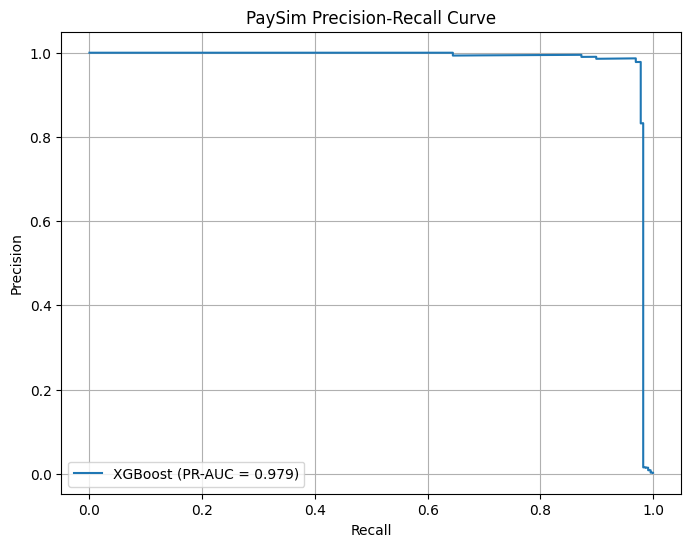

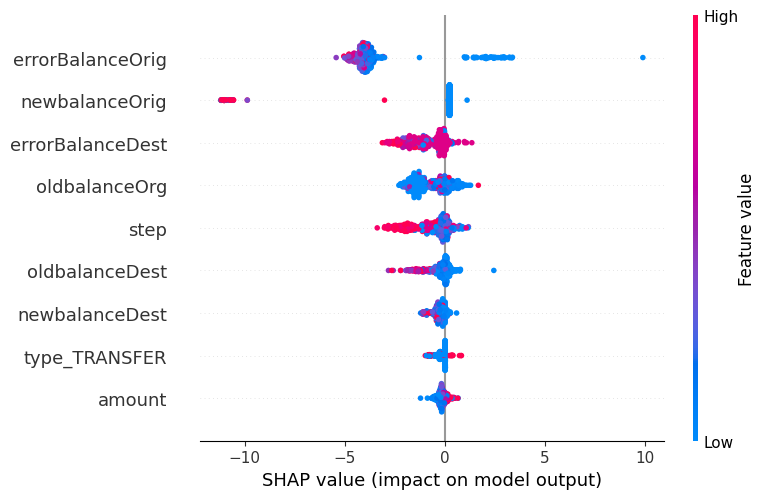

In [1]:
import pandas as pd
import numpy as np
import time
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.metrics import (
    classification_report, confusion_matrix, 
    precision_recall_curve, average_precision_score, 
    roc_auc_score, recall_score
)

# 1. Load Processed Test Data & Saved Models
X_test = pd.read_csv('../data/processed/X_test.csv')
y_test = pd.read_csv('../data/processed/y_test.csv').values.ravel()

xgb_model = joblib.load('../models/xgboost_paysim.pkl')
lgb_model = joblib.load('../models/lightgbm_paysim.pkl')

# 2. Measure Single-Transaction Latency (<100ms Requirement)
def measure_latency(model, sample_data, runs=1000):
    single_sample = sample_data.iloc[[0]]
    start_time = time.time()
    for _ in range(runs):
        _ = model.predict_proba(single_sample)
    end_time = time.time()
    avg_latency_ms = ((end_time - start_time) / runs) * 1000
    return avg_latency_ms

xgb_latency = measure_latency(xgb_model, X_test)
lgb_latency = measure_latency(lgb_model, X_test)

print(f"XGBoost Avg Single-Transaction Latency: {xgb_latency:.3f} ms")
print(f"LightGBM Avg Single-Transaction Latency: {lgb_latency:.3f} ms")

# 3. Model Performance Evaluation
def evaluate_model(model, X, y, model_name):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]
    
    cm = confusion_matrix(y, y_pred)
    tn, fp, fn, tp = cm.ravel()
    fpr = (fp / (fp + tn)) * 100
    pr_auc = average_precision_score(y, y_prob)
    roc_auc = roc_auc_score(y, y_prob)
    recall = recall_score(y, y_pred)
    
    print(f"\n================ {model_name} PaySim Results ================")
    print(f"Precision-Recall AUC (PR-AUC) : {pr_auc:.4f}")
    print(f"ROC-AUC Score                : {roc_auc:.4f}")
    print(f"Fraud Recall (Sensitivity)    : {recall * 100:.2f}%")
    print(f"False Positive Rate (FPR)     : {fpr:.4f}%")
    print(f"Confusion Matrix:\n", cm)
    
    return y_prob

xgb_probs = evaluate_model(xgb_model, X_test, y_test, "XGBoost")
lgb_probs = evaluate_model(lgb_model, X_test, y_test, "LightGBM")

# 4. Save Precision-Recall Plot
precision, recall, _ = precision_recall_curve(y_test, xgb_probs)
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'XGBoost (PR-AUC = {average_precision_score(y_test, xgb_probs):.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PaySim Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.savefig('../reports/figures/pr_curve_paysim.png')
print("\nPR-AUC Plot saved to 'reports/figures/pr_curve_paysim.png'")

# 5. Explainable AI (SHAP Plot)
print("\n--- Generating SHAP Feature Importance ---")
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test.iloc[:500])

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test.iloc[:500], show=False)
plt.tight_layout()
plt.savefig('../reports/figures/shap_summary_paysim.png')
print("SHAP Plot saved to 'reports/figures/shap_summary_paysim.png'")